# 09. Comparación en validación y anticipación de alertas

Este paso completa las métricas de la segunda entrega: comparación con la línea base, F1 por componente y tiempo de anticipación con alertas sostenidas. Usamos las mismas **144,000 horas de validación**. Prueba permanece fuera del análisis.

Conservamos una configuración por arquitectura: la de mayor PR-AUC a 24 horas en el notebook 08. No hacemos otra búsqueda. El reporte se redactará después de revisar estas salidas. Las figuras y tablas se muestran aquí; no se exportan archivos de resultados.

## 1. Preparar las herramientas y recuperar los modelos

Si abrimos este notebook con el mismo kernel que ejecutó el 08, podemos reutilizar `preparacion` y `resultados`. Abrir otro notebook no garantiza compartir kernel: el código lo comprueba. En una sesión nueva se reconstruyen únicamente los tres ensayos seleccionados, con las reglas y semilla originales. Esto puede tardar; no necesitamos repetir los ocho ensayos.

No guardamos los modelos en disco. Las salidas visibles se conservan al guardar el notebook, pero los objetos de Python solo existen mientras siga abierta su sesión.

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Conservar etiquetas claras al utilizar las figuras en el reporte.
plt.rcParams["figure.dpi"] = 200
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, classification_report)

# Localizar el proyecto desde su raíz o desde Modelación.
actual = Path.cwd()
ruta_repo = actual if (actual / "Datos").is_dir() else actual.parent
assert (ruta_repo / "Datos").is_dir()
for carpeta in ["Preprocesamiento", "Modelación"]:
    if str(ruta_repo / carpeta) not in sys.path:
        sys.path.insert(0, str(ruta_repo / carpeta))

from preparar_secuencias import preparar_secuencias
from entrenamiento_secuencial import entrenar_ensayo, indices_comunes

# Conservar la preparación de la sesión anterior cuando esté disponible.
if "preparacion" not in globals():
    preparacion = preparar_secuencias(ruta_repo)
if "resultados" not in globals():
    resultados = {}
configuracion_09 = {"semilla": 42, "hilos": 1, "batch_size": 512, "max_epocas": 6,
                    "paciencia": 2, "min_delta": 0.0001, "learning_rate": 0.001,
                    "weight_decay": 0.0001, "dropout": 0.10}
seleccionados = [("LSTM", 24, "focal"), ("TCN", 24, "ponderada"),
                ("CNN-LSTM", 24, "ponderada")]
clases = ["ninguno", "comp1", "comp2", "comp3", "comp4"]
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 5)

# No cambiar la configuración seleccionada a partir de las nuevas métricas.
import torch
torch.set_num_threads(configuracion_09["hilos"])
indices_09 = indices_comunes(preparacion)
for clave in seleccionados:
    if clave not in resultados:
        resultados[clave] = entrenar_ensayo(preparacion, indices_09, *clave, configuracion_09)
    else:
        print("Se reutiliza:", clave)

resumen_reconstruccion = pd.DataFrame([resultados[k]["resumen"] for k in seleccionados])
display(resumen_reconstruccion[["arquitectura", "L", "estrategia", "mejor_epoca", "PR_AUC_AP"]])

INICIO LSTM | L=24 | focal
LSTM | L=24 | focal época 1 lotes 300 / 1101
LSTM | L=24 | focal época 1 lotes 600 / 1101
LSTM | L=24 | focal época 1 lotes 900 / 1101
LSTM | L=24 | focal FIN época 1 PR-AUC 0.466701 segundos 16.6
LSTM | L=24 | focal época 2 lotes 300 / 1101
LSTM | L=24 | focal época 2 lotes 600 / 1101
LSTM | L=24 | focal época 2 lotes 900 / 1101
LSTM | L=24 | focal FIN época 2 PR-AUC 0.858883 segundos 17.7
LSTM | L=24 | focal época 3 lotes 300 / 1101
LSTM | L=24 | focal época 3 lotes 600 / 1101
LSTM | L=24 | focal época 3 lotes 900 / 1101
LSTM | L=24 | focal FIN época 3 PR-AUC 0.982926 segundos 15.8
LSTM | L=24 | focal época 4 lotes 300 / 1101
LSTM | L=24 | focal época 4 lotes 600 / 1101
LSTM | L=24 | focal época 4 lotes 900 / 1101
LSTM | L=24 | focal FIN época 4 PR-AUC 0.987971 segundos 16.6
LSTM | L=24 | focal época 5 lotes 300 / 1101
LSTM | L=24 | focal época 5 lotes 600 / 1101
LSTM | L=24 | focal época 5 lotes 900 / 1101
LSTM | L=24 | focal FIN época 5 PR-AUC 0.989817 se

,arquitectura,L,estrategia,mejor_epoca,PR_AUC_AP
0,LSTM,24,focal,6,0.99439
1,TCN,24,ponderada,6,0.99619
2,CNN-LSTM,24,ponderada,6,0.99751


Las estrategias seleccionadas son LSTM con focal, TCN con ponderada y CNN-LSTM con ponderada. Usamos 24 horas porque fue la longitud inicial para las tres arquitecturas y la mejor de las longitudes comparadas en CNN-LSTM. Esta selección ya usó validación: las nuevas métricas siguen siendo resultados de desarrollo.

## 2. Reproducir la línea base sin cambiar sus decisiones

Volvemos a ajustar regresión logística y XGBoost con exactamente las celdas de preparación y entrenamiento del notebook 05. No ejecutamos sus gráficas ni leemos prueba. Reutilizar esas celdas evita escribir otra versión de la línea base con parámetros diferentes.

La línea base usa sus 580,200 filas de entrenamiento y 31 entradas. Las redes usan 563,500 anclas comunes y 13 canales horarios más las entradas estáticas. Todas se evalúan en las mismas horas de validación. La comparación es de los procedimientos construidos, no un experimento que aísle solo la arquitectura.

La línea base se ajusta en un proceso de Python separado para evitar interferencias entre las bibliotecas nativas de XGBoost y PyTorch. Solo intercambiamos probabilidades mediante un archivo temporal que se elimina al terminar; no se exportan modelos ni resultados permanentes.

In [2]:
import subprocess
import tempfile

# Recuperar las celdas originales del 05 en otro proceso, con los mismos parámetros.
# El proceso separado mantiene independiente el ajuste de XGBoost y el de PyTorch.
codigo_base = r"""
import os
import sys
from pathlib import Path
import nbformat
import numpy as np
os.chdir(sys.argv[1])
notebook = nbformat.read(Path("Modelación") / "05_línea_base_clásica.ipynb", as_version=4)
espacio = {}
for numero in [2, 4, 7, 9, 11]:
    celda = notebook.cells[numero]
    assert celda.cell_type == "code"
    exec(compile(celda.source, "linea_base_05", "exec"), espacio)
np.savez_compressed(sys.argv[2],
    logistica_bin=espacio["probabilidades_binarias"]["Regresión logística"],
    logistica_multi=espacio["probabilidades_multiclase"]["Regresión logística"],
    xgb_bin=espacio["probabilidades_binarias"]["XGBoost"],
    xgb_multi=espacio["probabilidades_multiclase"]["XGBoost"])
"""

# El archivo de intercambio vive fuera del repositorio y se borra automáticamente.
with tempfile.TemporaryDirectory() as temporal:
    archivo_temporal = Path(temporal) / "probabilidades.npz"
    ejecucion_base = subprocess.run(
        [sys.executable, "-c", codigo_base, str(ruta_repo), str(archivo_temporal)],
        capture_output=True, text=True,
    )
    if ejecucion_base.returncode != 0:
        raise RuntimeError("La línea base no terminó correctamente; revisar el proceso antes de continuar.")
    print(ejecucion_base.stdout)
    with np.load(archivo_temporal) as archivo:
        probabilidades_base = {nombre: archivo[nombre].copy() for nombre in archivo.files}

# Alinear todas las probabilidades con la misma máquina, hora y etiquetas.
claves = ["machineID", "datetime"]
validacion_base = pd.read_csv(ruta_repo / "Datos" / "Datos_preparados" / "validación.csv", parse_dates=["datetime"])
orden_base = validacion_base.sort_values(claves).index.to_numpy()
referencia = validacion_base.iloc[orden_base].reset_index(drop=True)
predicciones_09 = {}
for nombre, prefijo in [("Regresión logística", "logistica"), ("XGBoost", "xgb")]:
    predicciones_09[nombre] = {"binaria": probabilidades_base[prefijo + "_bin"][orden_base],
                              "multiclase": probabilidades_base[prefijo + "_multi"][orden_base]}
for clave in seleccionados:
    arquitectura, longitud, estrategia = clave
    tabla = preparacion["anclas"][longitud]["validación"].reset_index(drop=True)
    orden = tabla.sort_values(claves).index.to_numpy()
    tabla = tabla.iloc[orden].reset_index(drop=True)
    pd.testing.assert_frame_equal(tabla[claves], referencia[claves], check_dtype=False)
    pred = resultados[clave]["predicciones"]
    assert np.array_equal(pred["y_binaria"][orden], referencia["etiqueta_binaria"])
    assert np.array_equal(pred["y_multiclase"][orden], referencia["etiqueta_multiclase"].map(dict(zip(clases, range(5)))))
    predicciones_09[arquitectura] = {"binaria": pred["prob_binaria"][orden],
                                    "multiclase": pred["prob_multiclase"][orden]}
assert len(referencia) == 144000
print("Cinco procedimientos alineados en las mismas 144,000 horas de validación.")

                     entrenamiento  validación
volt_media_3h                  200           0
volt_desv_3h                   200           0
rotate_media_3h                200           0
rotate_desv_3h                 200           0
pressure_media_3h              200           0
pressure_desv_3h               200           0
vibration_media_3h             200           0
vibration_desv_3h              200           0
volt_media_24h                2300           0
volt_desv_24h                 2300           0
rotate_media_24h              2300           0
rotate_desv_24h               2300           0
pressure_media_24h            2300           0
pressure_desv_24h             2300           0
vibration_media_24h           2300           0
vibration_desv_24h            2300           0
        conjunto   filas  positivos
0  entrenamiento  580200      11742
1     validación  144000       2652
Variables numéricas: 30
Variable categórica: ['model']
     clase  código
0  ninguno       0


## 3. Métricas por hora y por componente

La PR-AUC se calcula como average precision. Para cada modelo elegimos el umbral que maximiza recall entre los que logran precisión de al menos 0.80 en validación, igual que en el 05. Este umbral es de desarrollo, no una política operativa validada de forma independiente.

La clase multiclase es la de mayor probabilidad. Mostramos F1 de cada componente, su promedio sin `ninguno` y el promedio de las cinco clases. El promedio de componentes se calcula sobre todas las horas, de modo que también penaliza predecir componentes en horas sanas. Las etiquetas siguen siendo de clase única: los empates de componentes se resuelven como en el paso 04.

,modelo,PR_AUC_AP,ROC_AUC,umbral,precision,recall_precision_080,F1_macro_5_clases,F1_macro_componentes
0,Regresión logística,0.79685,0.99659,0.99056,0.80030,0.40196,0.61237,0.51995
1,XGBoost,0.99856,0.99997,0.10526,0.80024,0.99849,0.99463,0.99331
2,LSTM,0.99439,0.99984,0.11276,0.80012,0.99472,0.95415,0.94281
3,TCN,0.99619,0.99993,0.00109,0.80000,1.00000,0.97624,0.97043
4,CNN-LSTM,0.99751,0.99996,0.00446,0.80000,1.00000,0.97551,0.96952


,modelo,componente,precision,recall,F1,horas_reales
0,Regresión logística,comp1,0.16605,0.98394,0.28414,498
1,Regresión logística,comp2,0.55307,0.98426,0.70819,1080
2,Regresión logística,comp3,0.34539,0.98592,0.51157,426
3,Regresión logística,comp4,0.41022,0.96605,0.57590,648
4,XGBoost,comp1,0.97446,0.99598,0.98510,498
5,XGBoost,comp2,1.00000,1.00000,1.00000,1080
6,XGBoost,comp3,1.00000,0.99765,0.99882,426
7,XGBoost,comp4,0.97885,1.00000,0.98931,648
8,LSTM,comp1,0.87427,0.90763,0.89064,498
9,LSTM,comp2,0.95575,1.00000,0.97738,1080


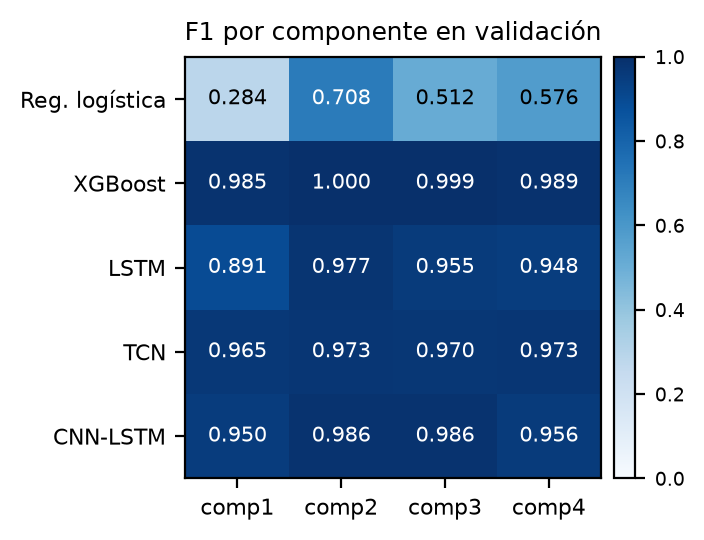

In [3]:
def seleccionar_umbral(y, p):
    """Mayor recall entre umbrales reales con precisión de al menos 0.80."""
    precision, recall, umbrales = precision_recall_curve(y, p)
    candidatos = np.flatnonzero(precision[:-1] >= 0.80)
    if len(candidatos) == 0:
        return None
    posicion = candidatos[np.argmax(recall[:-1][candidatos])]
    return float(umbrales[posicion])


y_bin = referencia["etiqueta_binaria"].to_numpy(dtype=int)
y_multi = referencia["etiqueta_multiclase"].map(dict(zip(clases, range(5)))).to_numpy(dtype=int)
metricas_09 = []
detalle_09 = []
umbrales_09 = {}
for nombre, pred in predicciones_09.items():
    p = pred["binaria"]
    pm = pred["multiclase"]
    assert np.isfinite(p).all() and np.isfinite(pm).all()
    assert np.allclose(pm.sum(axis=1), 1, atol=1e-5)
    umbral = seleccionar_umbral(y_bin, p)
    umbrales_09[nombre] = umbral
    clase_predicha = pm.argmax(axis=1)
    fila = {"modelo": nombre, "PR_AUC_AP": average_precision_score(y_bin, p),
            "ROC_AUC": roc_auc_score(y_bin, p), "umbral": umbral,
            "precision": np.nan, "recall_precision_080": np.nan,
            "F1_macro_5_clases": f1_score(y_multi, clase_predicha, labels=range(5), average="macro", zero_division=0),
            "F1_macro_componentes": f1_score(y_multi, clase_predicha, labels=[1, 2, 3, 4], average="macro", zero_division=0)}
    if umbral is not None:
        alerta = p >= umbral
        fila["precision"] = precision_score(y_bin, alerta, zero_division=0)
        fila["recall_precision_080"] = recall_score(y_bin, alerta)
        assert fila["precision"] >= 0.80 - 1e-12
    metricas_09.append(fila)
    informe = classification_report(y_multi, clase_predicha, labels=range(5), target_names=clases,
                                    output_dict=True, zero_division=0)
    for componente in clases[1:]:
        datos_clase = informe[componente]
        detalle_09.append({"modelo": nombre, "componente": componente,
                          "precision": datos_clase["precision"], "recall": datos_clase["recall"],
                          "F1": datos_clase["f1-score"], "horas_reales": int(datos_clase["support"])})
metricas_09 = pd.DataFrame(metricas_09)
detalle_09 = pd.DataFrame(detalle_09)
display(metricas_09.round(5))
display(detalle_09.round(5))

# Mostrar los componentes en una figura legible dentro del reporte de dos columnas.
tabla_f1 = detalle_09.pivot(index="modelo", columns="componente", values="F1")
tabla_f1 = tabla_f1.loc[list(predicciones_09), clases[1:]]
fig, eje = plt.subplots(figsize=(3.6, 2.8))
imagen = eje.imshow(tabla_f1.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
eje.set(xticks=range(4), xticklabels=clases[1:], yticks=range(5),
        yticklabels=["Reg. logística", "XGBoost", "LSTM", "TCN", "CNN-LSTM"],
        title="F1 por componente en validación")
eje.tick_params(labelsize=8)
eje.title.set_fontsize(9)
for fila in range(5):
    for columna in range(4):
        valor = tabla_f1.iloc[fila, columna]
        eje.text(columna, fila, f"{valor:.3f}", ha="center", va="center",
                 fontsize=7.5, color="white" if valor > .65 else "black")
barra = fig.colorbar(imagen, ax=eje, fraction=.05, pad=.03)
barra.ax.tick_params(labelsize=7)
fig.tight_layout()
plt.show()

La mejor red por PR-AUC fue **CNN-LSTM**, con **0.9975**, frente a **0.9986** de XGBoost y **0.7969** de regresión logística. En esta validación, las redes no superaron la mejor línea base en PR-AUC.

El F1 macro de componentes de XGBoost fue **0.9933**; el de CNN-LSTM, **0.9695**. Este promedio excluye `ninguno`, pero los falsos positivos sobre horas sanas siguen afectando el F1 de cada componente. El mejor modelo por PR-AUC no tiene por qué ser el mejor en cada componente o en F1 macro.

Las métricas binaria y multiclase evalúan cabezas diferentes. Una mejora de PR-AUC binaria no demuestra por sí sola una mejora al identificar componentes. Todas las decisiones de selección y umbral se hicieron en validación, sin una evaluación independiente en prueba.

## 4. Qué cuenta como una alerta sostenida

Una hora supera el umbral si su probabilidad es mayor o igual al umbral elegido. Una alerta se **confirma en la tercera hora consecutiva** que lo supera. Por ejemplo, si se supera a las 08:00, 09:00 y 10:00, confirmamos a las 10:00. Si la falla ocurre a las 16:00, la anticipación es **6 horas**, no 8: a las 08:00 aún no conocíamos las otras dos predicciones.

Cada racha continua genera una sola alerta. Una hora por debajo del umbral o un salto en el registro rompe la racha. No contamos cada hora de una racha larga como una alerta nueva.

Asociamos cada alerta a la siguiente hora de falla de su máquina solo si ocurre después y dentro de las próximas 24 horas. La hora de falla no puede alertar sobre sí misma. Si varias alertas apuntan al mismo evento, conservamos la primera confirmada. Si varios componentes fallan a la vez, contamos un único evento máquina-hora para la tarea binaria.

Para evaluar un evento exigimos sus 24 horas anteriores completas dentro de las anclas de validación. Los eventos de los bordes sin esa cobertura quedan fuera del denominador. Una alerta confirmada antes de esa ventana no se vuelve a emitir retrospectivamente al entrar en ella. No usamos fallas de noviembre ni información de prueba.

In [4]:
def confirmar_alertas(tabla, probabilidades, umbral):
    """Emitir una sola confirmación al completar tres horas consecutivas sobre el umbral."""
    columnas = ["machineID", "confirmacion"]
    if umbral is None:
        return pd.DataFrame(columns=columnas)
    temporal = tabla[["machineID", "datetime"]].copy()
    temporal["supera"] = probabilidades >= umbral
    confirmaciones = []
    for maquina, grupo in temporal.groupby("machineID", sort=True):
        racha = 0
        anterior = None
        for hora, supera in zip(grupo["datetime"], grupo["supera"]):

            # Reiniciar ante un hueco horario; nunca unir rachas de máquinas distintas.
            if anterior is not None and hora - anterior != pd.Timedelta(hours=1):
                racha = 0
            racha = racha + 1 if supera else 0
            if racha == 3:
                confirmaciones.append({"machineID": maquina, "confirmacion": hora})
            anterior = hora
    return pd.DataFrame(confirmaciones, columns=columnas)


def asociar_alertas(alertas, eventos):
    """Asignar cada alerta solo a la siguiente falla, sin reutilizarla para otra posterior."""
    asociaciones = []
    for maquina, grupo in alertas.groupby("machineID", sort=True):
        fallas = eventos.loc[eventos["machineID"] == maquina, "datetime"].sort_values().to_numpy()
        for confirmacion in grupo["confirmacion"]:
            posicion = fallas.searchsorted(confirmacion.to_datetime64(), side="right")
            if posicion < len(fallas):
                falla = pd.Timestamp(fallas[posicion])
                horas = (falla - confirmacion).total_seconds() / 3600
                if 0 < horas <= 24:
                    asociaciones.append({"machineID": maquina, "datetime": falla,
                                         "confirmacion": confirmacion, "anticipacion_h": horas})
    columnas = ["machineID", "datetime", "confirmacion", "anticipacion_h"]
    return pd.DataFrame(asociaciones, columns=columnas)


# Comprobar la regla con ejemplos conocidos, sin entrenar ni ajustar umbrales.
ejemplo = pd.DataFrame({"machineID": [1] * 6, "datetime": pd.date_range("2015-09-05 08:00", periods=6, freq="h")})
a = confirmar_alertas(ejemplo, np.array([.9, .9, .9, .9, .1, .9]), .8)
assert len(a) == 1 and a.iloc[0]["confirmacion"] == pd.Timestamp("2015-09-05 10:00")
f = pd.DataFrame({"machineID": [1, 1], "datetime": pd.to_datetime(["2015-09-05 16:00", "2015-09-05 17:00"])})
asociacion = asociar_alertas(a, f)
assert len(asociacion) == 1 and asociacion.iloc[0]["anticipacion_h"] == 6
assert asociacion.iloc[0]["datetime"] == pd.Timestamp("2015-09-05 16:00")
con_hueco = ejemplo.iloc[[0, 1, 3]].copy()
assert confirmar_alertas(con_hueco, np.ones(3), .8).empty
assert asociar_alertas(a, pd.DataFrame({"machineID": [1], "datetime": [pd.Timestamp("2015-09-05 10:00")]})).empty
print("Verificaciones correctas: tercera hora, una alerta por racha, huecos y falla estrictamente futura.")

Verificaciones correctas: tercera hora, una alerta por racha, huecos y falla estrictamente futura.


Estas comprobaciones evitan anticipación artificial: no fechamos la alerta dos horas antes de que pudiera confirmarse y no extendemos una racha a través de horas ausentes. La anticipación que calculamos es de detección binaria; no exige que el componente predicho sea correcto.

## 5. Medir cobertura de eventos y anticipación

Mostramos cuántos eventos elegibles se detectaron y cuántos no, junto con mediana y cuartiles de anticipación. La mediana se calcula **solo entre eventos detectados**, por eso siempre debe leerse junto con la cobertura. No damos anticipación cero a una falla que no se detectó.

La precisión mínima de 0.80 se refiere a predicciones por hora antes de exigir la racha. No garantiza precisión de 0.80 por episodio ni una tasa operativa de falsas alarmas. Aquí no calculamos ahorro, intervenciones evitadas ni una política final.

**Importante:** «no detectado» en esta tabla significa que no se asoció una confirmación dentro de las 24 horas previas. Puede haber una racha ya confirmada antes de ese horizonte. Revisamos ese caso por separado para no confundir ausencia de alerta válida con ausencia absoluta de señal.

,registros_falla,eventos_maquina_hora,eventos_elegibles,excluidos_sin_24h_completas
0,118,112,108,4


,modelo,eventos_elegibles,detectados,no_detectados,cobertura,anticipacion_q25_h,anticipacion_mediana_h,anticipacion_q75_h
0,Regresión logística,108,68,40,0.6296,12.0,21.0,22.0
1,XGBoost,108,98,10,0.9074,22.0,22.0,22.0
2,LSTM,108,100,8,0.9259,22.0,22.0,22.0
3,TCN,108,101,7,0.9352,22.0,22.0,22.0
4,CNN-LSTM,108,105,3,0.9722,22.0,22.0,22.0


/var/folders/m0/9hmx0jw1693068pfqrhn3_3c0000gn/T/ipykernel_22217/3922641396.py:48: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ejes[1].boxplot([valores], positions=[i], vert=False, widths=.5, showfliers=True)
/var/folders/m0/9hmx0jw1693068pfqrhn3_3c0000gn/T/ipykernel_22217/3922641396.py:48: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ejes[1].boxplot([valores], positions=[i], vert=False, widths=.5, showfliers=True)
/var/folders/m0/9hmx0jw1693068pfqrhn3_3c0000gn/T/ipykernel_22217/3922641396.py:48: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ejes[1].boxplot([valores], positions=[i], vert=False, widths=.5, showfliers=True)
/var/folders/m0/9hmx0jw16930

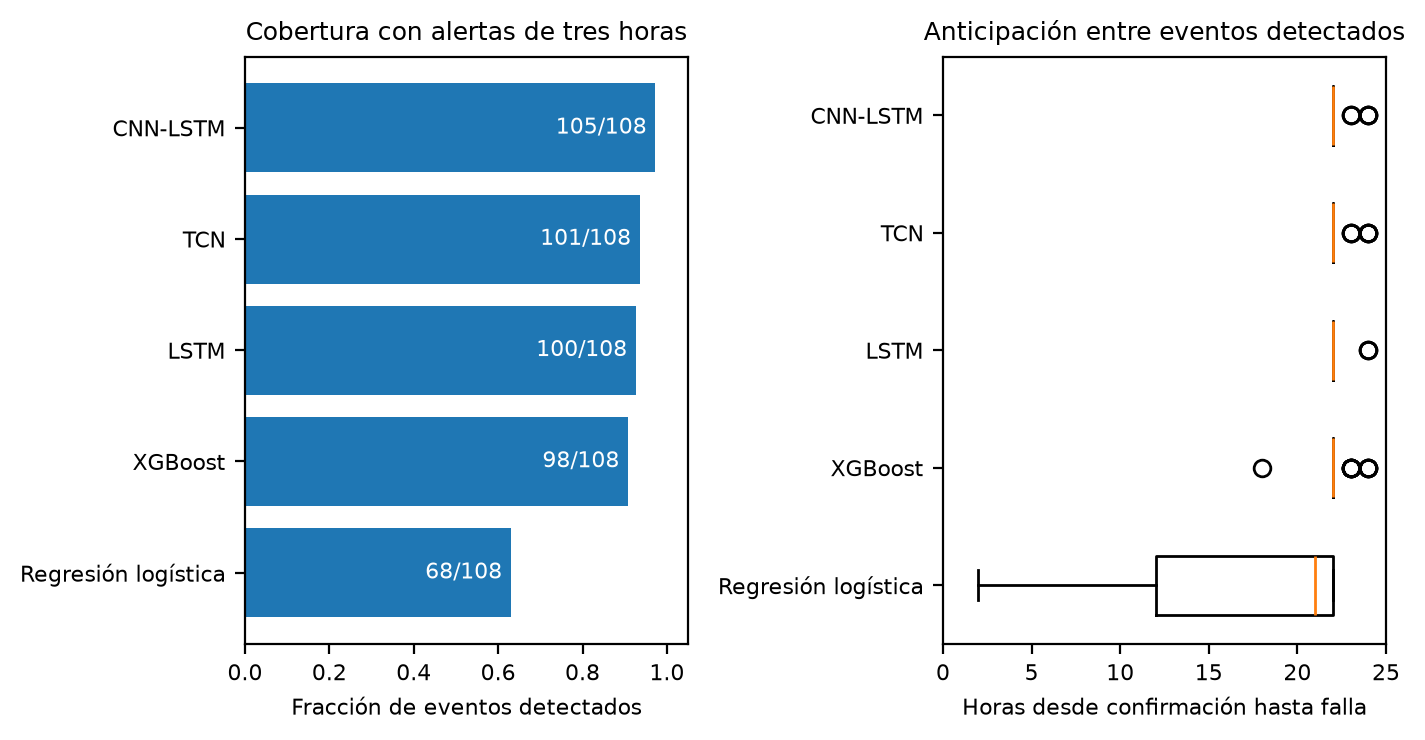

,modelo,sin_confirmacion_valida,alerta_previa_activa,otros_sin_confirmacion
0,Regresión logística,40,1,39
1,XGBoost,10,10,0
2,LSTM,8,8,0
3,TCN,7,7,0
4,CNN-LSTM,3,3,0


In [5]:
# Leer fallas históricas y limitar los eventos a septiembre-octubre.
fallas_09 = pd.read_csv(ruta_repo / "Datos" / "PdM_failures.csv", parse_dates=["datetime"])
fallas_09 = fallas_09.loc[fallas_09["datetime"].between("2015-09-01", "2015-11-01", inclusive="left")].copy()
eventos_09 = fallas_09[["machineID", "datetime"]].drop_duplicates().sort_values(claves).reset_index(drop=True)

# Exigir que las 24 horas previas estén disponibles para predecir dentro de validación.
indices_por_maquina = {maquina: pd.DatetimeIndex(grupo["datetime"])
                       for maquina, grupo in referencia.groupby("machineID")}
elegibles = []
for evento in eventos_09.itertuples(index=False):
    requeridas = pd.date_range(evento.datetime - pd.Timedelta(hours=24), periods=24, freq="h")
    if requeridas.isin(indices_por_maquina[evento.machineID]).all():
        elegibles.append({"machineID": evento.machineID, "datetime": evento.datetime})
elegibles_09 = pd.DataFrame(elegibles)
assert not elegibles_09.duplicated(claves).any()
display(pd.DataFrame({"registros_falla": [len(fallas_09)], "eventos_maquina_hora": [len(eventos_09)],
                      "eventos_elegibles": [len(elegibles_09)],
                      "excluidos_sin_24h_completas": [len(eventos_09) - len(elegibles_09)]}))

resumen_alertas_09 = []
detalle_eventos_09 = {}
for nombre, pred in predicciones_09.items():
    alertas = confirmar_alertas(referencia, pred["binaria"], umbrales_09[nombre])
    asociaciones = asociar_alertas(alertas, eventos_09)
    primeras = asociaciones.sort_values("confirmacion").drop_duplicates(claves, keep="first")
    detalle = elegibles_09.merge(primeras, on=claves, how="left", validate="one_to_one")
    detectados = detalle["anticipacion_h"].dropna()
    assert detectados.between(0, 24, inclusive="right").all()
    detalle_eventos_09[nombre] = detalle
    resumen_alertas_09.append({"modelo": nombre, "eventos_elegibles": len(detalle),
                               "detectados": len(detectados), "no_detectados": len(detalle) - len(detectados),
                               "cobertura": len(detectados) / len(detalle),
                               "anticipacion_q25_h": detectados.quantile(.25),
                               "anticipacion_mediana_h": detectados.median(),
                               "anticipacion_q75_h": detectados.quantile(.75)})
resumen_alertas_09 = pd.DataFrame(resumen_alertas_09)
display(resumen_alertas_09.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(7.2, 3.8))
nombres = list(predicciones_09)
ejes[0].barh(nombres, resumen_alertas_09.set_index("modelo").loc[nombres, "cobertura"])
ejes[0].set(xlabel="Fracción de eventos detectados", xlim=(0, 1.05), title="Cobertura con alertas de tres horas")
for i, nombre in enumerate(nombres):
    fila = resumen_alertas_09.set_index("modelo").loc[nombre]
    ejes[0].text(fila["cobertura"] - .02, i, f'{int(fila["detectados"])}/{int(fila["eventos_elegibles"])}', va="center", ha="right", color="white", fontsize=8)
    valores = detalle_eventos_09[nombre]["anticipacion_h"].dropna()
    if len(valores):
        ejes[1].boxplot([valores], positions=[i], vert=False, widths=.5, showfliers=True)
ejes[1].set(yticks=range(len(nombres)), yticklabels=nombres, xlabel="Horas desde confirmación hasta falla",
             xlim=(0, 25), title="Anticipación entre eventos detectados")
for eje in ejes:
    eje.tick_params(labelsize=8)
    eje.title.set_fontsize(9)
    eje.xaxis.label.set_fontsize(8)
fig.tight_layout()
plt.show()

# Distinguir falta de una confirmación válida y una alerta ya activa antes del horizonte.
# Es un diagnóstico de la regla; no se reemiten alertas ni se cambian sus métricas.
diagnostico_alertas_09 = []
for nombre, pred in predicciones_09.items():
    alertas = confirmar_alertas(referencia, pred["binaria"], umbrales_09[nombre])
    sin_confirmacion = detalle_eventos_09[nombre].loc[lambda tabla: tabla["anticipacion_h"].isna()]
    previas_activas = 0
    for evento in sin_confirmacion.itertuples(index=False):
        inicio_ventana = evento.datetime - pd.Timedelta(hours=24)
        anteriores = alertas.loc[(alertas["machineID"] == evento.machineID) &
                                 (alertas["confirmacion"] < inicio_ventana), "confirmacion"]
        if len(anteriores) == 0:
            continue
        confirmacion = anteriores.max()
        fin_revision = inicio_ventana + pd.Timedelta(hours=2)
        seleccion = ((referencia["machineID"] == evento.machineID) &
                     (referencia["datetime"] >= confirmacion) &
                     (referencia["datetime"] <= fin_revision))
        horas = pd.DatetimeIndex(referencia.loc[seleccion, "datetime"])
        esperadas = pd.date_range(confirmacion, fin_revision, freq="h")

        # La racha debe continuar sin huecos desde su confirmación hasta entrar en la ventana.
        continua = horas.equals(esperadas)
        supera = (pred["binaria"][seleccion.to_numpy()] >= umbrales_09[nombre]).all()
        if continua and supera:
            previas_activas += 1
    diagnostico_alertas_09.append({"modelo": nombre,
                                  "sin_confirmacion_valida": len(sin_confirmacion),
                                  "alerta_previa_activa": previas_activas,
                                  "otros_sin_confirmacion": len(sin_confirmacion) - previas_activas})
diagnostico_alertas_09 = pd.DataFrame(diagnostico_alertas_09)
display(diagnostico_alertas_09)


Los **118 registros de falla** de septiembre-octubre representan **112 eventos máquina-hora**. Se evaluaron **108** con historia de validación completa; **4** quedaron fuera por los bordes.

- **Regresión logística:** 68 de 108 eventos (63.0%), con mediana de **21.0 horas** y cuartiles **12.0–22.0 horas** entre los detectados.
- **XGBoost:** 98 de 108 eventos (90.7%), con mediana de **22.0 horas** y cuartiles **22.0–22.0 horas** entre los detectados.
- **LSTM:** 100 de 108 eventos (92.6%), con mediana de **22.0 horas** y cuartiles **22.0–22.0 horas** entre los detectados.
- **TCN:** 101 de 108 eventos (93.5%), con mediana de **22.0 horas** y cuartiles **22.0–22.0 horas** entre los detectados.
- **CNN-LSTM:** 105 de 108 eventos (97.2%), con mediana de **22.0 horas** y cuartiles **22.0–22.0 horas** entre los detectados.

Una mediana alta no compensa eventos no detectados: la tabla muestra ambas cosas. Tampoco significa que el componente se identificó correctamente ni que exista tiempo suficiente para una intervención real. Los resultados dependen de la regla explícita de confirmación, el horizonte de 24 horas y los umbrales elegidos en validación.

**Diagnóstico de las rachas:** los 10 casos sin confirmación válida de XGBoost y los 3 de CNN-LSTM tenían una alerta confirmada antes de las 24 horas previas que seguía activa al entrar en la ventana. La política no la reemite, por lo que no la acredita dentro del horizonte. Lo mismo ocurrió en los 8 casos de LSTM y los 7 de TCN. En regresión logística fue 1 de sus 40 casos. Esta diferencia de cobertura depende del momento de confirmación y no demuestra que las otras redes nunca hubieran advertido esas fallas.

## 6. Diagrama de la entrada para el reporte

El tensor dinámico contiene una ventana ordenada por máquina. La etiqueta corresponde a la última hora `t`; las entradas no incluyen las fallas futuras. Los cinco indicadores de error quedan en 0/1. Las estadísticas de los ocho canales continuos y de la antigüedad se aprenden solo con entrenamiento.

El siguiente esquema resume la preparación del notebook 06 y se conserva aquí para usarlo directamente en el reporte.

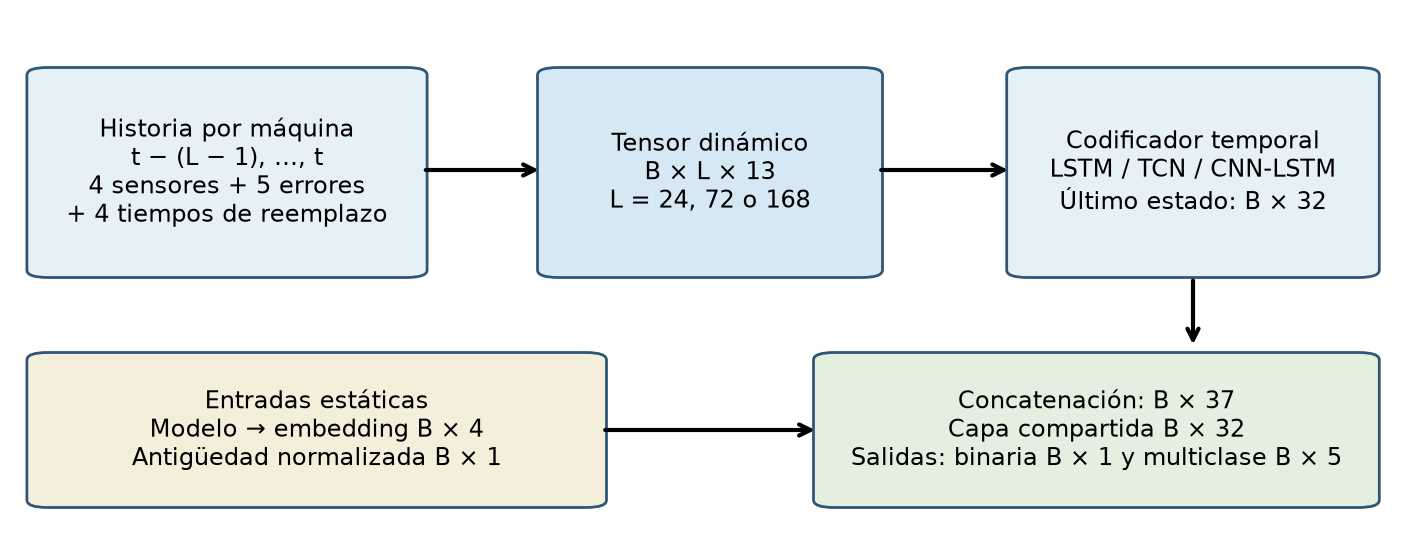

In [6]:
fig, eje = plt.subplots(figsize=(7.2, 2.8))
eje.axis("off")
def caja(x, y, ancho, alto, texto, color):
    eje.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.015", facecolor=color, edgecolor="#315675"))
    eje.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=8.5)

caja(.02, .50, .26, .39, "Historia por máquina\nt − (L − 1), …, t\n4 sensores + 5 errores\n+ 4 tiempos de reemplazo", "#e6f0f7")
caja(.39, .50, .22, .39, "Tensor dinámico\nB × L × 13\nL = 24, 72 o 168", "#d6e8f4")
caja(.73, .50, .24, .39, "Codificador temporal\nLSTM / TCN / CNN-LSTM\nÚltimo estado: B × 32", "#e6f0f7")
caja(.02, .04, .39, .28, "Entradas estáticas\nModelo → embedding B × 4\nAntigüedad normalizada B × 1", "#f4efdb")
caja(.59, .04, .38, .28, "Concatenación: B × 37\nCapa compartida B × 32\nSalidas: binaria B × 1 y multiclase B × 5", "#e3efdf")
for inicio, fin in [((.29, .70), (.38, .70)), ((.62, .70), (.72, .70)),
                    ((.85, .49), (.85, .34)), ((.42, .18), (.58, .18))]:
    eje.annotate("", xy=fin, xytext=inicio, arrowprops={"arrowstyle": "->", "lw": 1.5})
eje.set(xlim=(0, 1), ylim=(0, 1))
fig.tight_layout()
plt.show()

### Diagramas de las arquitecturas para el reporte

Se reutiliza el esquema del notebook 07 con dimensiones de impresión. Solo cambia el tamaño del dibujo: las capas, entradas y salidas son las mismas. No se vuelve a entrenar.

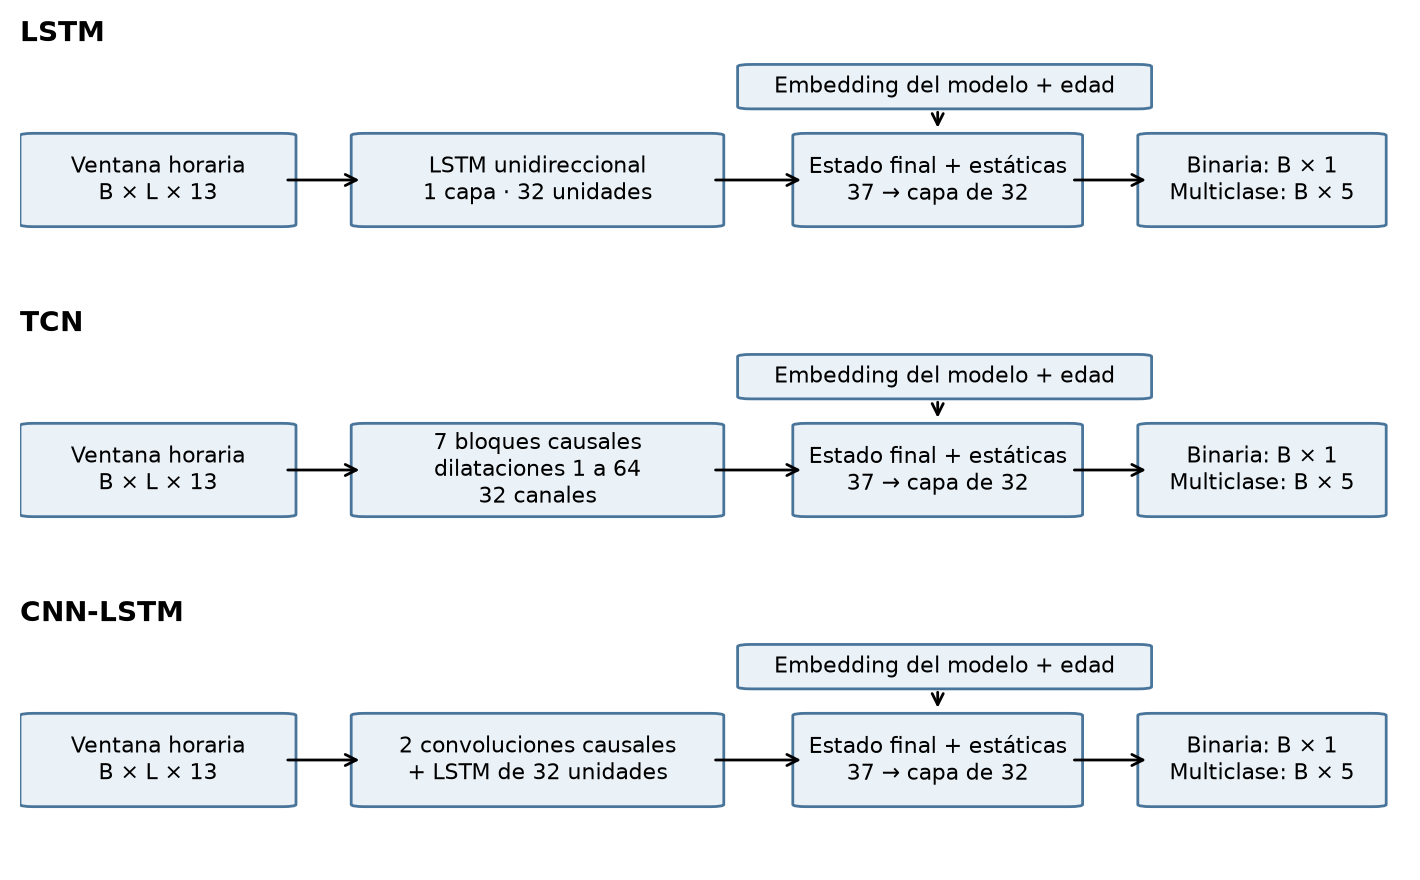

In [7]:
# Dibujar los esquemas dentro del notebook, sin guardar imágenes por separado.
fig, ejes = plt.subplots(3, 1, figsize=(7.2, 4.5))
descripciones = {
    "LSTM": "LSTM unidireccional\n1 capa · 32 unidades",
    "TCN": "7 bloques causales\ndilataciones 1 a 64\n32 canales",
    "CNN-LSTM": "2 convoluciones causales\n+ LSTM de 32 unidades",
}
for eje, (nombre, detalle) in zip(ejes, descripciones.items()):
    eje.set_xlim(0, 1)
    eje.set_ylim(0, 1)
    eje.axis("off")
    eje.set_title(nombre, loc="left", fontweight="bold", fontsize=10)
    cajas = [(0.01, 0.25, 0.18, 0.40, "Ventana horaria\nB × L × 13"),
             (0.25, 0.25, 0.25, 0.40, detalle),
             (0.57, 0.25, 0.19, 0.40, "Estado final + estáticas\n37 → capa de 32"),
             (0.82, 0.25, 0.16, 0.40, "Binaria: B × 1\nMulticlase: B × 5"),
             (0.53, 0.78, 0.28, 0.18, "Embedding del modelo + edad")]
    for x, y, ancho, alto, texto in cajas:
        caja = FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.01",
                              facecolor="#eaf1f7", edgecolor="#49759a")
        eje.add_patch(caja)
        eje.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=8)
    for comienzo, fin in [(0.19, 0.25), (0.50, 0.57), (0.76, 0.82)]:
        eje.annotate("", xy=(fin, 0.45), xytext=(comienzo, 0.45), arrowprops={"arrowstyle": "->"})
    eje.annotate("", xy=(0.665, 0.66), xytext=(0.665, 0.78), arrowprops={"arrowstyle": "->"})
fig.tight_layout()
plt.show()

## 7. Conclusiones y límites

Las redes lograron resultados altos, pero **XGBoost mantuvo la mayor PR-AUC**. La CNN-LSTM seleccionada obtiene F1 macro de componentes **0.9695**, mientras XGBoost obtiene **0.9933**. Las tablas permiten evaluar también cobertura y anticipación; no se utiliza únicamente una métrica para afirmar superioridad.

Una explicación plausible de la ventaja clásica es que las variables históricas ya resumen señales claras del conjunto simulado. La comparación no aísla solo la arquitectura: difieren representación, número de anclas de entrenamiento y presupuesto. No se realizó una nueva búsqueda después de ver las métricas adicionales.

El conjunto de prueba no se abrió ni se utilizó para elegir modelos, umbrales o reglas. Las métricas por hora y por evento usan validación; no son evidencia de ahorro real ni de desempeño en planta. 